,observations,moyenne_pm25,moyenne_PM10,moyenne_SO2,moyenne_NO2,moyenne_CO,moyenne_O3
station,,,,,,,
Dongsi,35064,86.19,110.34,18.53,53.70,1330.07,57.21
Wanshouxigong,35064,85.02,112.22,17.15,55.53,1370.40,56.23
Nongzhanguan,35064,84.84,108.99,18.69,58.10,1324.35,58.53
Gucheng,35064,83.85,118.86,15.37,55.87,1323.97,57.69
Wanliu,35064,83.37,110.46,18.38,65.26,1319.35,48.87
Guanyuan,35064,82.93,109.02,17.59,57.90,1271.29,55.80
Aotizhongxin,35064,82.77,110.06,17.38,59.31,1262.95,56.35
Tiantan,35064,82.16,106.36,14.37,53.16,1298.30,55.98
Shunyi,35064,79.49,98.74,13.57,43.91,1187.06,55.20


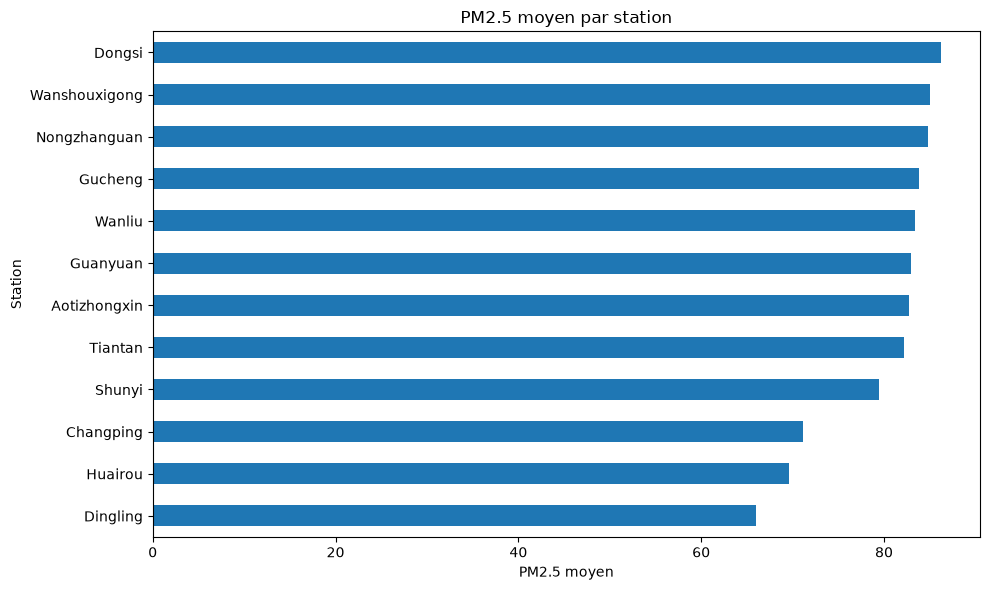

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_file = Path(
    r"C:\Users\ADMIN\Desktop\AirWatch\analytics\outputs\prepared_data\observations_clean.parquet"
)
df = pd.read_parquet(data_file)

pollutants = ["pm25", "PM10", "SO2", "NO2", "CO", "O3"]
available = [column for column in pollutants if column in df.columns]

station_stats = df.groupby("station").agg(
    observations=("event_time", "count"),
    **{f"moyenne_{column}": (column, "mean") for column in available},
).round(2)

display(station_stats.sort_values("moyenne_pm25", ascending=False))

station_stats["moyenne_pm25"].sort_values().plot.barh(figsize=(10, 6))
plt.title("PM2.5 moyen par station")
plt.xlabel("PM2.5 moyen")
plt.ylabel("Station")
plt.tight_layout()
plt.show()